# Лабораторная работа 3. Зависимость коэффициента липофильности от структуры молекул (линейная регрессия, МНК)

Модель: $\log P = \beta_0 + \beta_1 x_1 + \dots + \beta_{24} x_{24} + \varepsilon$, оценка — метод наименьших квадратов $b = (X^TX)^{-1}X^Ty$. Все основные вычисления выполнены «вручную» на `numpy`; `sklearn`/`scipy` используются только для проверки и для квантилей распределения Стьюдента.

## 1. Изучение данных

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

df = pd.read_csv("lipo.csv")
df["Вещество"] = df["Вещество"].str.strip()
print("Размер выборки:", df.shape, "| пропусков:", int(df.isna().sum().sum()), "| дубликатов веществ:", int(df["Вещество"].duplicated().sum()))
df.head()

Размер выборки: (82, 26) | пропусков: 0 | дубликатов веществ: 0


,Вещество,logP,RNH2,R2NH,R3N,ROPO3,ROH,RCHO,RCOR,RCOOH,RCOOR,ROR,RSO2NR,RSR,RF,RCl,RBr,RSO2R,C,RINGS,AROMATIC,HBA1,HBA2,HBD,PSA,MR
0,Acetamide,-1.26,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,2,2,1,43.09,14.6354
1,Acetanilide,1.16,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8,1,1,2,2,1,29.10,40.7547
2,Acetazolamide,-0.26,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,4,1,1,7,8,2,151.66,45.2161
3,Acetic acid,-0.17,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,2,0,0,2,2,1,37.30,13.4998
4,Acetohexamide,2.44,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,15,2,1,6,6,2,100.72,82.6509


In [2]:
feat = list(df.columns[2:])           # 24 регрессора
y = df["logP"].values.astype(float)
X = df[feat].values.astype(float)
n, k = X.shape
print(f"n = {n} наблюдений, k = {k} регрессоров, число степеней свободы остатков n-k-1 = {n-k-1}")
df[["logP"]+feat].describe().T.round(3)

n = 82 наблюдений, k = 24 регрессоров, число степеней свободы остатков n-k-1 = 57


,count,mean,std,min,25%,50%,75%,max
logP,82.0,1.560,1.602,-1.80,0.545,1.680,2.330,6.900
RNH2,82.0,0.256,0.466,0.00,0.000,0.000,0.000,2.000
R2NH,82.0,0.354,0.596,0.00,0.000,0.000,1.000,2.000
R3N,82.0,0.146,0.389,0.00,0.000,0.000,0.000,2.000
ROPO3,82.0,0.012,0.110,0.00,0.000,0.000,0.000,1.000
ROH,82.0,0.134,0.343,0.00,0.000,0.000,0.000,1.000
RCHO,82.0,0.012,0.110,0.00,0.000,0.000,0.000,1.000
RCOR,82.0,0.085,0.322,0.00,0.000,0.000,0.000,2.000
RCOOH,82.0,0.061,0.241,0.00,0.000,0.000,0.000,1.000
RCOOR,82.0,0.049,0.217,0.00,0.000,0.000,0.000,1.000


ROPO3        1
RCHO         1
RBr          1
RSO2R        2
RF           3
RCOOR        4
RCOOH        5
RCOR         6
RSR         10
RCl         10
R3N         11
ROH         11
RNH2        20
R2NH        24
ROR         28
RSO2NR      50
HBD         60
AROMATIC    70
RINGS       72
HBA1        76
HBA2        78
PSA         78
C           82
MR          82


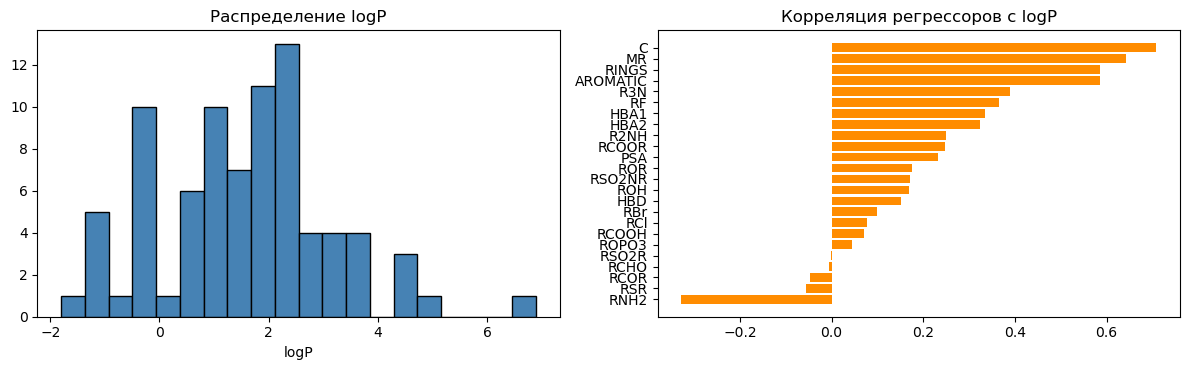

In [3]:
# Частота ненулевых значений бинарных/счётных групп: редкие регрессоры будут оценены неточно
nz = (df[feat]!=0).sum().sort_values()
print(nz.to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(y, bins=20, color="steelblue", edgecolor="k"); ax[0].set_title("Распределение logP"); ax[0].set_xlabel("logP")
c = df[["logP"]+feat].corr()["logP"].drop("logP").sort_values()
ax[1].barh(c.index, c.values, color="darkorange"); ax[1].set_title("Корреляция регрессоров с logP"); plt.tight_layout()

## 2. Оценки МНК $b_i$

In [4]:
X1 = np.column_stack([np.ones(n), X])          # матрица плана с константой
names = ["const"] + feat
XtX_inv = np.linalg.inv(X1.T @ X1)
print("Ранг матрицы плана:", np.linalg.matrix_rank(X1), "из", X1.shape[1], "| число обусловленности:", round(np.linalg.cond(X1), 1))
b = XtX_inv @ X1.T @ y
pd.DataFrame({"b": b}, index=names).round(4)

Ранг матрицы плана: 25 из 25 | число обусловленности: 2423.1


,b
const,0.0756
RNH2,0.1526
R2NH,0.0970
R3N,-0.2417
ROPO3,1.1465
ROH,0.0536
RCHO,0.0546
RCOR,-0.5381
RCOOH,0.9024
RCOOR,0.2458


## 3. МНК-остатки $e$

In [5]:
y_hat = X1 @ b
e = y - y_hat
print("Сумма остатков (должна быть ≈0):", e.sum())
print("X^T e (ортогональность, макс. |.|):", np.abs(X1.T @ e).max())
pd.DataFrame({"Вещество": df["Вещество"], "logP": y, "logP_модель": y_hat.round(3), "e": e.round(3)}).head(15)

Сумма остатков (должна быть ≈0): -1.217872469538861e-10
X^T e (ортогональность, макс. |.|): 1.0585722520772833e-08


,Вещество,logP,logP_модель,e
0,Acetamide,-1.260,-0.665,-0.595
1,Acetanilide,1.160,1.620,-0.460
2,Acetazolamide,-0.260,-0.945,0.685
3,Acetic acid,-0.170,0.586,-0.756
4,Acetohexamide,2.440,1.254,1.186
5,Acetone,-0.240,-0.093,-0.147
6,Acetophenone,1.580,1.144,0.436
7,Amprenavir,2.200,2.686,-0.486
8,Aniline,0.900,0.746,0.154
9,Anisole,2.110,1.530,0.580


## 4. Дисперсия ошибки $s^2$ и стандартная ошибка регрессии $s$

In [6]:
df_res = n - k - 1
RSS = e @ e
s2 = RSS / df_res
s = np.sqrt(s2)
print(f"RSS = {RSS:.4f}\ns^2 = RSS/(n-k-1) = {s2:.4f}\ns = {s:.4f}")

RSS = 33.6849
s^2 = RSS/(n-k-1) = 0.5910
s = 0.7687


## 5. Коэффициент детерминации $R^2$

In [7]:
TSS = ((y - y.mean())**2).sum()
R2 = 1 - RSS/TSS
R2_adj = 1 - (RSS/df_res)/(TSS/(n-1))
F = ((TSS-RSS)/k)/(RSS/df_res); pF = stats.f.sf(F, k, df_res)
print(f"R^2 = {R2:.4f}\nскорректированный R^2 = {R2_adj:.4f}\nF({k},{df_res}) = {F:.2f}, p-value = {pF:.2e}")

R^2 = 0.8380
скорректированный R^2 = 0.7698
F(24,57) = 12.28, p-value = 9.00e-15


## 6. Доверительные интервалы (95 %) на основе $t$-статистики

$b_j \pm t_{1-\alpha/2,\,n-k-1}\, s\sqrt{[(X^TX)^{-1}]_{jj}}$

In [8]:
alpha = 0.05
se = s * np.sqrt(np.diag(XtX_inv))
t_stat = b / se
t_crit = stats.t.ppf(1 - alpha/2, df_res)
p_val = 2 * stats.t.sf(np.abs(t_stat), df_res)
res = pd.DataFrame({"b": b, "SE": se, "t": t_stat, "p": p_val, "CI_low": b - t_crit*se, "CI_high": b + t_crit*se}, index=names)
res["значим (5%)"] = np.where(res.p < alpha, "да", "нет")
print("t_крит =", round(t_crit, 4))
res.round(4)

t_крит = 2.0025


,b,SE,t,p,CI_low,CI_high,значим (5%)
const,0.0756,0.2537,0.2979,0.7669,-0.4324,0.5836,нет
RNH2,0.1526,0.4261,0.3580,0.7217,-0.7008,1.0059,нет
R2NH,0.0970,0.3801,0.2553,0.7994,-0.6641,0.8581,нет
R3N,-0.2417,0.5350,-0.4517,0.6532,-1.3129,0.8296,нет
ROPO3,1.1465,1.2217,0.9384,0.3520,-1.3000,3.5930,нет
ROH,0.0536,0.4448,0.1205,0.9045,-0.8370,0.9443,нет
RCHO,0.0546,0.8166,0.0669,0.9469,-1.5807,1.6899,нет
RCOR,-0.5381,0.3483,-1.5450,0.1279,-1.2356,0.1593,нет
RCOOH,0.9024,0.4882,1.8484,0.0697,-0.0752,1.8800,нет
RCOOR,0.2458,0.7943,0.3094,0.7581,-1.3447,1.8363,нет


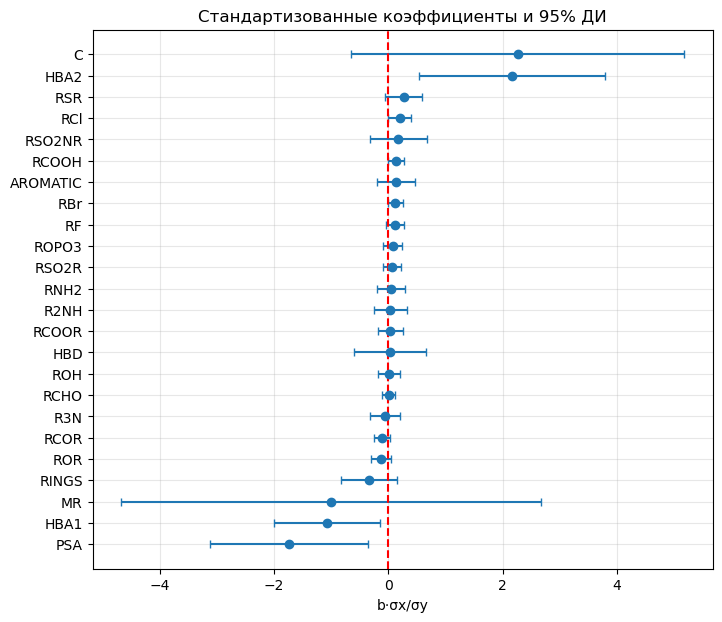

In [9]:
# Графическое представление ДИ (по стандартизованным коэффициентам, чтобы масштабы были сопоставимы)
sx = X.std(axis=0, ddof=1)
sb = b[1:]*sx/y.std(ddof=1); sci = np.c_[res.CI_low[1:]*sx, res.CI_high[1:]*sx]/y.std(ddof=1)
o = np.argsort(sb)
plt.figure(figsize=(8, 7))
plt.errorbar(sb[o], range(k), xerr=[sb[o]-sci[o,0], sci[o,1]-sb[o]], fmt="o", capsize=3)
plt.yticks(range(k), np.array(feat)[o]); plt.axvline(0, color="r", ls="--")
plt.title("Стандартизованные коэффициенты и 95% ДИ"); plt.xlabel("b·σx/σy"); plt.grid(alpha=.3)

In [10]:
# Проверка собственной реализации независимой библиотекой
from sklearn.linear_model import LinearRegression
lr = LinearRegression().fit(X, y)
print("max|b_manual - b_sklearn| =", np.abs(np.r_[lr.intercept_, lr.coef_] - b).max(), "| R2 sklearn =", round(lr.score(X, y), 4))

max|b_manual - b_sklearn| = 2.0725643423702422e-11 | R2 sklearn = 0.838


## 7. Анализ результатов
### 7.1 Вклад регрессоров

In [11]:
imp = pd.DataFrame({"b": b[1:], "std-коэфф.": sb, "|t|": np.abs(t_stat[1:]), "p": p_val[1:]}, index=feat)
imp.sort_values("|t|", ascending=False).round(4)

,b,std-коэфф.,|t|,p
HBA2,1.0234,2.1586,2.6543,0.0103
PSA,-0.0533,-1.7410,2.5249,0.0144
HBA1,-0.4321,-1.0712,2.3320,0.0233
RCl,0.9564,0.1965,1.8969,0.0629
RCOOH,0.9024,0.1356,1.8484,0.0697
RBr,1.7566,0.1211,1.8310,0.0723
RSR,1.3211,0.2715,1.6880,0.0969
C,0.4278,2.2624,1.5531,0.1259
RCOR,-0.5381,-0.1082,1.5450,0.1279
ROR,-0.2740,-0.1266,1.4787,0.1447


### 7.2 Проверка условий применимости МНК (условия Гаусса–Маркова и нормальность)

In [12]:
# (а) мультиколлинеарность: VIF_j = 1/(1-R_j^2)
def r2_of(target, Z):
    Z1 = np.column_stack([np.ones(len(Z)), Z]); bb = np.linalg.lstsq(Z1, target, rcond=None)[0]
    r = target - Z1@bb; return 1 - r@r/((target-target.mean())**2).sum()
vif = pd.Series({f: 1/(1-r2_of(X[:, j], np.delete(X, j, 1))) for j, f in enumerate(feat)}).sort_values(ascending=False)
print("VIF (топ-8):"); print(vif.head(8).round(1).to_string())

# (б) нормальность остатков
sw = stats.shapiro(e); print(f"\nШапиро–Уилк: W = {sw.statistic:.4f}, p = {sw.pvalue:.4f}")
# (в) автокорреляция (Дарбин–Уотсон; порядок строк — алфавитный, поэтому смысл условный)
dw = np.sum(np.diff(e)**2)/np.sum(e**2); print(f"Дарбин–Уотсон: {dw:.3f}")
# (г) гетероскедастичность (Бройш–Паган, LM = n·R^2 вспомогательной регрессии e^2 ~ X)
LM = n*r2_of(e**2, X); print(f"Бройш–Паган: LM = {LM:.2f}, p = {stats.chi2.sf(LM, k):.4f}")
# (д) влиятельные наблюдения
H = X1 @ XtX_inv @ X1.T; h = np.diag(H)
cook = (e**2/(s2*(k+1))) * h/(1-h)**2
inf = pd.DataFrame({"h_ii": h, "Cook": cook, "e": e}, index=df["Вещество"]).sort_values("Cook", ascending=False)
print("\nПорог для рычагов 2(k+1)/n =", round(2*(k+1)/n, 3), "| порог Кука 4/n =", round(4/n, 3))
inf.head(6).round(3)

VIF (топ-8):
MR        1183.8
C          746.6
HBA2       232.7
PSA        167.3
HBA1        74.2
HBD         34.4
RSO2NR      21.7
RINGS       20.6

Шапиро–Уилк: W = 0.9749, p = 0.1075
Дарбин–Уотсон: 2.083
Бройш–Паган: LM = 25.81, p = 0.3627

Порог для рычагов 2(k+1)/n = 0.61 | порог Кука 4/n = 0.049


,h_ii,Cook,e
Вещество,,,
Benzaldehyde,1.000,20938.480,0.000
Bromobenzene,1.000,5023.873,-0.000
Fosamprenavir,1.000,1060.644,-0.000
Brinzolamide,0.388,0.272,-1.974
Glycopyramide,0.371,0.109,-1.314
Dronedarone,0.467,0.108,-0.985


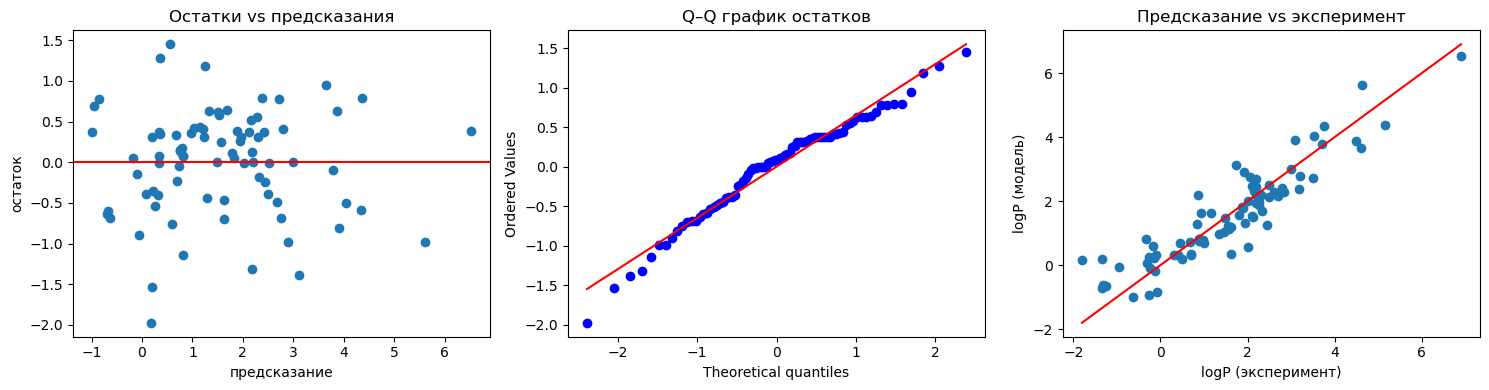

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_hat, e); ax[0].axhline(0, color="r"); ax[0].set_xlabel("предсказание"); ax[0].set_ylabel("остаток"); ax[0].set_title("Остатки vs предсказания")
stats.probplot(e, plot=ax[1]); ax[1].set_title("Q–Q график остатков")
ax[2].scatter(y, y_hat); lim=[y.min(), y.max()]; ax[2].plot(lim, lim, "r"); ax[2].set_xlabel("logP (эксперимент)"); ax[2].set_ylabel("logP (модель)"); ax[2].set_title("Предсказание vs эксперимент")
plt.tight_layout()

### 7.3 Обобщающая способность: перекрёстная проверка

На обучающей выборке $R^2$ с 24 регрессорами при $n=82$ завышен, поэтому проверим предсказание на «невидимых» веществах. Замечание: RCHO, RBr и ROPO3 встречаются ровно в одном веществе (см. п. 1), у этих трёх веществ рычаг $h_{ii}=1$, остаток равен нулю, и классическая формула LOO через $h_{ii}$ неприменима. Поэтому делаем честную 10-fold проверку с пересчётом модели (`lstsq` — решение минимальной нормы, если регрессор в обучающей части отсутствует), повторённую 20 раз.

In [14]:
rng = np.random.default_rng(0)
def cv_rmse(X1, y, folds=10, reps=20):
    out = []; pred_all = np.zeros(len(y))
    for r in range(reps):
        idx = rng.permutation(len(y)); pred = np.zeros(len(y))
        for f in np.array_split(idx, folds):
            tr = np.setdiff1d(idx, f)
            bb = np.linalg.lstsq(X1[tr], y[tr], rcond=None)[0]
            pred[f] = X1[f] @ bb
        out.append(np.sqrt(np.mean((y-pred)**2))); pred_all += pred/reps
    return np.mean(out), np.std(out), pred_all
m, sd, pcv = cv_rmse(X1, y)
Q2 = 1 - np.sum((y-pcv)**2)/TSS
print(f"RMSE на обучении = {np.sqrt(RSS/n):.3f}")
print(f"RMSE 10-fold CV  = {m:.3f} ± {sd:.3f}")
print(f"Q^2 (по усреднённым CV-предсказаниям) = {Q2:.3f}; для сравнения R^2 = {R2:.3f}")
print(f"Разброс logP: std = {y.std(ddof=1):.3f}")

RMSE на обучении = 0.641
RMSE 10-fold CV  = 1.010 ± 0.041
Q^2 (по усреднённым CV-предсказаниям) = 0.615; для сравнения R^2 = 0.838
Разброс logP: std = 1.602


## 8. Выводы

**Адекватность модели.** Модель в целом значима: $R^2 = 0{,}838$, скорректированный $R^2 = 0{,}770$, $F(24;57)=12{,}3$, $p\approx 9\cdot10^{-15}$; стандартная ошибка регрессии $s = 0{,}77$ единицы logP при разбросе самого logP $\sigma = 1{,}60$. Однако при 24 регрессорах и 82 веществах $R^2$ на обучающей выборке оптимистичен: при 10-fold проверке RMSE растёт с 0,64 до ≈1,01, а $Q^2\approx 0{,}6$. Вывод: линейная модель **удовлетворительна для грубой оценки липофильности** (объясняет порядка 60 % дисперсии на новых веществах), но слишком переобучена и не годится для точных прогнозов.

**Вклад регрессоров.** На уровне 5 % значимы только три: HBA2 ($b=+1{,}02$), HBA1 ($b=-0{,}43$) и PSA ($b=-0{,}053$). Доверительные интервалы остальных 21 коэффициента содержат ноль. По стандартизованным коэффициентам наибольший вклад у C (2,26), HBA2 (2,16), PSA (−1,74), HBA1 (−1,07) и MR (−1,01); наименьший — у RCHO, ROH, HBD, RCOOR, R2NH, RNH2. Согласие с химическими представлениями **частичное**: отрицательный вклад полярной поверхности PSA, а также рост logP с числом атомов углерода и галогенов (RCl, RBr, RF) соответствуют теории. Но у ROH, HBD, аминогрупп коэффициенты близки к нулю или положительны, а HBA1 и HBA2 имеют противоположные знаки, C положителен при отрицательном MR — такие «компенсирующие» пары типичны для мультиколлинеарности, и по отдельным коэффициентам нельзя судить о физическом механизме. Малые вклады ROH, RCHO, ROPO3, RBr вызваны ещё и тем, что эти группы встречаются в 1–11 веществах из 82 (RCHO, RBr, ROPO3 — ровно в одном, поэтому их коэффициенты просто «подгоняют» это вещество, а доверительные интервалы для них неинформативны).

**Условия применимости МНК.**
- Ранг матрицы плана полный (25), оценки существуют и несмещены; ✔.
- Нормальность остатков не отвергается (Шапиро–Уилк, $p=0{,}11$); ✔ — $t$-интервалы корректны.
- Гомоскедастичность не отвергается (Бройш–Паган, $p=0{,}36$); ✔.
- Автокорреляция: $DW=2{,}08$, но порядок веществ алфавитный и физического смысла не имеет; условие считаем выполненным.
- **Мультиколлинеарность сильная — условие нарушено по духу:** VIF у MR ≈ 1184, C ≈ 747, HBA2 ≈ 233, PSA ≈ 167 (норма < 10). Это объясняет широкие ДИ и незначимость большинства коэффициентов при высоком $R^2$ и значимом $F$.
- Малое отношение $n/k\approx 3{,}4$ и три вещества с рычагом $h_{ii}=1$ (Benzaldehyde, Bromobenzene, Fosamprenavir — единственные носители RCHO, RBr, ROPO3) делают модель неустойчивой. Возможные улучшения: отбор признаков (LASSO/пошаговая регрессия), удаление MR или C, ридж-регрессия.

**Сравнение с работой [2].** Тот же набор из 24 дескрипторов и та же форма модели использованы, как в статье; качественно результат согласуется: линейная MLR-модель даёт умеренную точность, ключевую роль играют размер молекулы (C/MR), полярность (PSA) и водородные связи (HBA/HBD). Точные численные значения коэффициентов и метрик из статьи в предоставленных материалах отсутствуют, поэтому количественное сопоставление (RMSE/R² статьи с нашими 0,64 / 0,84 на обучении и 1,01 по CV) нужно дополнить по тексту статьи вручную. Также отметим, что в ТЗ указан натуральный логарифм, а значения в lipo.csv (напр. бензол 2,13) соответствуют десятичному $\log_{10} P$; на сам МНК это не влияет (отличие — константный множитель 2,303).

## Приложение. Использование генеративного ИИ (промт)

Задание выполнено с помощью Claude (Anthropic). Промт пользователя:

> Сделай эти две лаб работы. На выходе должно быть два notebook (блокнот с кодом и всеми результатами работы программы согласно техническому заданию) для каждой лаб работы соответственно. Также здесь некоторые пожелания от преподавателя (Совсем забыл сказать: генеративным ИИ можно пользоваться для всего кроме тестов, контрактов (если они будут) и документации. Если будете пользоваться, приложите к отчёту промты.) Мне надо чтобы ты сделал все за меня, так что просто учти это... Уложись в рамках лимита пожалуйста
> (к промту были приложены файлы lab3.pdf, lab4.pdf, lipo.csv)